# 4 · Validazione su immagini sintetiche

I dati reali non hanno una verità a terra: l'errore misurato mescola l'algoritmo e il setup. Qui la scena è nota: una camera con i parametri stimati sul setup reale, un master di cerchi, una lama di luce e un solido con profilo nominale. `lightsheet3d.synthetic` genera le immagini con gli stessi nomi e formato di quelle reali, la pipeline le legge senza modifiche e il risultato si confronta con la geometria vera.

Il rumore è uno spostamento gaussiano (in pixel) dei centri dei cerchi e dei punti della lama prima del disegno.

In [1]:
import tempfile
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "docs" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from lightsheet3d.solids import CORPO6
from lightsheet3d.synthetic import Scene, evaluate, render_master, render_scan

## Immagini generate

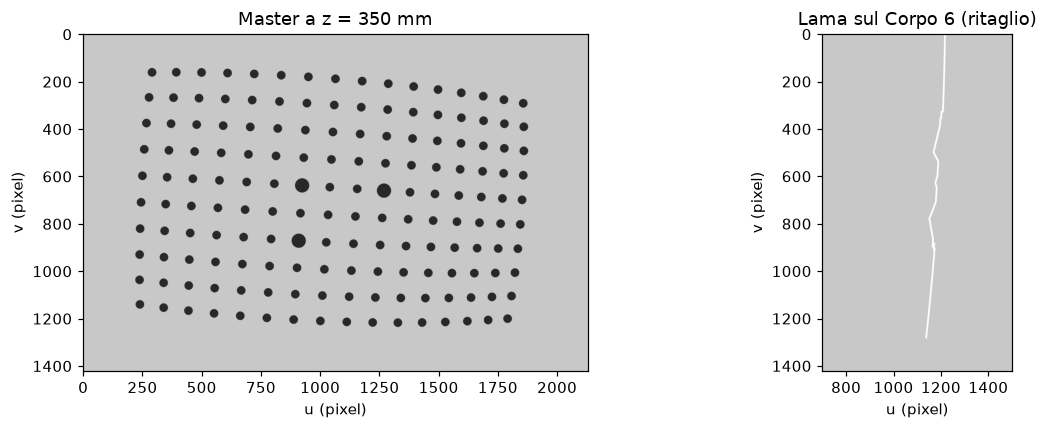

In [2]:
scene = Scene()
master = render_master(scene, 350)
scan = render_scan(scene, CORPO6, shift=-57.0)

fig, axs = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2.4, 1]})
axs[0].imshow(cv.cvtColor(master, cv.COLOR_BGR2RGB)); axs[0].set_title("Master a z = 350 mm")
axs[1].imshow(cv.cvtColor(scan[:, 700:1500], cv.COLOR_BGR2RGB), extent=(700, 1500, scan.shape[0], 0)); axs[1].set_title("Lama sul Corpo 6 (ritaglio)")
for ax in axs:
    ax.grid(False); ax.set(xlabel="u (pixel)", ylabel="v (pixel)")
fig.tight_layout(); fig.savefig(FIGURES / "synthetic_images.png", bbox_inches="tight")

## Errore contro rumore

Per ogni livello di rumore si genera un dataset (master a cinque quote, lama sul master, scansione), si calibra e si misura. L'errore è la distanza di ogni punto 3D dal profilo nominale vero, nel piano (y, h).

In [3]:
NOISE = [0.0, 0.25, 0.5, 1.0, 2.0]
SEEDS = range(3)
med, p90 = {}, {}
with tempfile.TemporaryDirectory() as tmp:
    for sigma in NOISE:
        runs = [evaluate(CORPO6, Path(tmp) / f"{sigma}_{seed}", noise_px=sigma, seed=seed) for seed in SEEDS]
        med[sigma] = [np.median(r["dist"]) for r in runs]
        p90[sigma] = [np.percentile(r["dist"], 90) for r in runs]
        print(f"rumore {sigma:4.2f} px: distanza mediana {np.mean(med[sigma]):.3f} mm, 90° percentile {np.mean(p90[sigma]):.3f} mm, "
              f"scarto traslazione {np.mean([abs(r['shift'] + 57) for r in runs]):.2f} mm")

rumore 0.00 px: distanza mediana 0.032 mm, 90° percentile 0.094 mm, scarto traslazione 0.03 mm


rumore 0.25 px: distanza mediana 0.097 mm, 90° percentile 0.407 mm, scarto traslazione 0.02 mm


rumore 0.50 px: distanza mediana 0.179 mm, 90° percentile 0.744 mm, scarto traslazione 0.04 mm


rumore 1.00 px: distanza mediana 0.352 mm, 90° percentile 1.243 mm, scarto traslazione 0.03 mm


rumore 2.00 px: distanza mediana 0.642 mm, 90° percentile 1.978 mm, scarto traslazione 0.12 mm


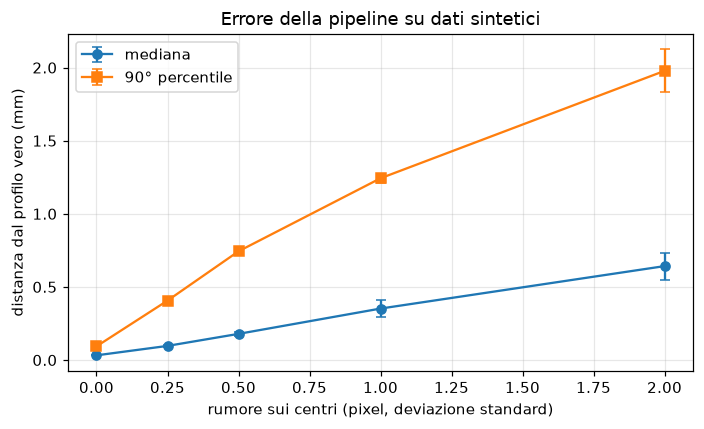

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for series, label, marker in ((med, "mediana", "o"), (p90, "90° percentile", "s")):
    mean = [np.mean(series[s]) for s in NOISE]
    spread = [np.ptp(series[s]) / 2 for s in NOISE]
    ax.errorbar(NOISE, mean, yerr=spread, marker=marker, capsize=3, label=label)
ax.set(xlabel="rumore sui centri (pixel, deviazione standard)", ylabel="distanza dal profilo vero (mm)",
       title="Errore della pipeline su dati sintetici"); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "synthetic_error_vs_noise.png", bbox_inches="tight")

## Estrazione della lama: baricentro contro Steger

Finora il rumore spostava i vertici della lama. Qui si simula quello che cambia davvero fra i due metodi: lama sfocata (`blur`, deviazione standard in pixel) e rumore gaussiano sulle intensità (`grain`, livelli di grigio). Il baricentro pesato (`laser_centroids`, il default) usa il nucleo saturo e i bordi; `laser_steger` cerca la cresta di luminosità con le derivate gaussiane e ricava la posizione sulla normale. Entrambi cercano la lama dove c'è il nucleo saturo, quindi trovano le stesse righe.

In [5]:
from lightsheet3d.laser import laser_centroids, laser_steger

CONDITIONS = {"nitida": {}, "sfocata\n(1.5 px)": {"blur": 1.5}, "sfocata +\ngrana (8)": {"blur": 1.5, "grain": 8}, "molto sfocata +\ngrana (12)": {"blur": 2.5, "grain": 12}}
EXTRACTORS = {"baricentro": laser_centroids, "Steger": laser_steger}
errors = {name: [] for name in EXTRACTORS}
with tempfile.TemporaryDirectory() as tmp:
    for cond, kw in CONDITIONS.items():
        for name, extract in EXTRACTORS.items():
            tag = cond.replace("\n", "_").replace(" ", "")
            runs = [evaluate(CORPO6, Path(tmp) / f"{tag}_{name}_{seed}", seed=seed, extract=extract, **kw) for seed in range(2)]
            errors[name].append(np.mean([np.median(r["dist"]) for r in runs]))
for i, cond in enumerate(CONDITIONS):
    print(f"{cond.replace(chr(10), ' '):28s} baricentro {errors['baricentro'][i]:.3f} mm | Steger {errors['Steger'][i]:.3f} mm")

nitida                       baricentro 0.032 mm | Steger 0.030 mm
sfocata (1.5 px)             baricentro 0.040 mm | Steger 0.030 mm
sfocata + grana (8)          baricentro 0.111 mm | Steger 0.063 mm
molto sfocata + grana (12)   baricentro 0.328 mm | Steger 0.171 mm


reale, Corpo 6: baricentro 0.546 mm | Steger 0.679 mm
reale, Corpo 5: baricentro 0.624 mm | Steger 0.619 mm


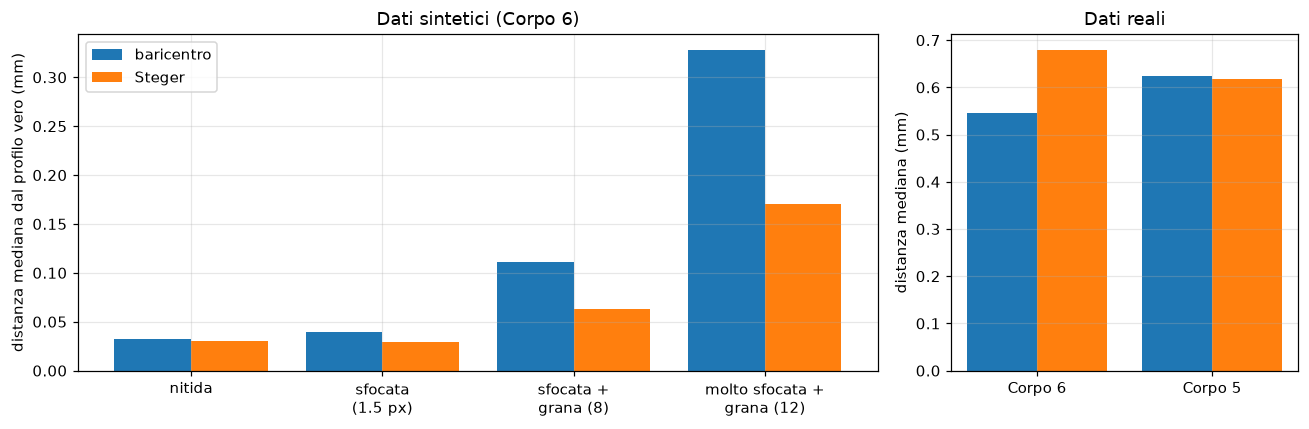

In [6]:
from lightsheet3d.measure import level_to_plate
from lightsheet3d.pipeline import PLATE_Z, calibrate_camera, calibrate_light_plane, scan_points
from lightsheet3d.solids import CORPO5, align, distances, nominal_curve

camera = calibrate_camera(ROOT / "data" / "camera_calibration")
real = {name: [] for name in EXTRACTORS}
for name, extract in EXTRACTORS.items():
    plane = calibrate_light_plane(ROOT / "data" / "light_plane_calibration", camera.model, extract=extract).plane
    for image, solid in (("30o34", CORPO6), ("30o3", CORPO5)):
        X = scan_points(ROOT / "data" / "scans" / f"{image}.jpg", camera.model, plane, extract=extract)
        y, h = X[:, 1], level_to_plate(X[:, 1], PLATE_Z - X[:, 2])
        sign, shift = align(solid, y, h)
        yn, _ = nominal_curve(solid, sign, shift)
        on_solid = (y > yn[1]) & (y < yn[-2])
        real[name].append(float(np.median(distances(solid, sign, shift, y[on_solid], h[on_solid]))))
for i, label in enumerate(("Corpo 6", "Corpo 5")):
    print(f"reale, {label}: baricentro {real['baricentro'][i]:.3f} mm | Steger {real['Steger'][i]:.3f} mm")

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [3, 1.3]})
x = np.arange(len(CONDITIONS))
for k, name in enumerate(EXTRACTORS):
    a.bar(x + 0.4 * (k - 0.5), errors[name], 0.4, label=name)
    b.bar(np.arange(2) + 0.4 * (k - 0.5), real[name], 0.4, label=name)
a.set(xticks=x, xticklabels=list(CONDITIONS), ylabel="distanza mediana dal profilo vero (mm)", title="Dati sintetici (Corpo 6)"); a.legend()
b.set(xticks=range(2), xticklabels=["Corpo 6", "Corpo 5"], ylabel="distanza mediana (mm)", title="Dati reali"); b.grid(True, alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURES / "stripe_extraction.png", bbox_inches="tight")

## Cosa mostra

* **Senza rumore** l'errore è di pochi centesimi di millimetro: restano la quantizzazione dei pixel e i fianchi molto ripidi, che hanno pochi punti.
* **Con rumore** l'errore cresce circa in proporzione: a 1 pixel la mediana è di circa 0.35 mm.
* **Cosa ha corretto questo notebook** (ogni punto ha un test in `tests/`):
  * la calibrazione inventava una deriva lineare dell'offset del master lungo z anche quando il master non si muoveva (errore sistematico di circa 0.25 mm senza rumore): ora `fit_camera` la rimuove;
  * le cime acute dei picchi risultavano sottostimate di circa 0.5 mm, perché la lama ha spessore e il baricentro per riga le taglia: ora `measure_peaks` le stima dall'intersezione dei fianchi (e dalla mediana dei punti sui piani larghi);
  * il baricentro della lama usava solo il nucleo saturo, con risoluzione di mezzo pixel: ora è pesato con l'intensità sui bordi;
  * il rilevatore di blob di OpenCV scartava i cerchi grandi dell'"L" quando il master era vicino alla camera.
* **Baricentro contro Steger**: con la lama sfocata e rumore sulle intensità Steger dimezza l'errore; sui dati reali, dove la lama è satura e ben contrastata, non c'è un vantaggio (Corpo 5 invariato, Corpo 6 un po' peggiore). Per questo il baricentro resta il default e Steger, 11 volte più lento, è un'opzione (`--extractor steger`).